# Example: The Farmer–Joshi Market
In this example, we simulate the Farmer–Joshi market, an agent-based model in which value investors and trend followers trade one asset through a market maker, and we compare the statistics of its growth rates with the stylized facts of real daily growth rates.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Simulate three markets:__ A Farmer–Joshi market has value investors, who trade on the gap between the price and their estimate of the value, and trend followers, who trade on recent price changes. A market maker turns their net order into a price change. We simulate markets with value investors only, trend followers only, and both groups, and compare their prices and growth rates.
> * __Measure the stylized facts:__ Fat tails and volatility clustering are patterns found in the growth rates of real assets. We measure the excess kurtosis and the autocorrelation of the growth rates, of their absolute values, and of the trading volume in the market with both groups.
> * __Compare with a real ticker and vary the mix of traders:__ The model has no data in it, only trading rules. We put the simulated statistics next to the same statistics for a real ticker, and vary the number of trend followers to see which statistics the model can match at the same time.

We use the trader parameters of [Farmer and Joshi (2002)](https://arxiv.org/pdf/cond-mat/0012419), Table 1, with two changes that we explain in the Constants section. Those two changes make this our variant of their simulation, not a replication.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

### Data
In Task 3, we compare the simulated market with the daily closing prices of one ticker from the course data set, 2014 to 2024. [The MyTrainingMarketDataSet() function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/data/#VLQuantitativeFinancePackage.MyTrainingMarketDataSet) returns a dictionary. Its `"dataset"` entry maps each ticker to a `DataFrame` of daily prices and volumes. We store it in the `dataset::Dict{String, DataFrame}` variable:

In [2]:
dataset = let

    # load the course data set: one DataFrame of daily prices and volumes per ticker -
    data = MyTrainingMarketDataSet()["dataset"];

    # return -
    data
end;

### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. Farmer and Joshi chose their parameters to keep the price near the value and to match the volatility of real prices. 

We make two changes:
* __Price noise:__ Table 1 lists a noise of 0.35 per step in the price, which is $\sigma_{S}\approx 5.6$ in our annualized units. Because the price in our simulations then drifts much farther from the value than in the paper's figures of price and value, we use $\sigma_{S}=0.8$. Try `σ_S = 5.6` to see the difference.
* __Value:__ Farmer and Joshi drive the value with annual S&P 500 dividends, interpolated to days. We use a random walk instead.

Every other trader parameter is the Table 1 value, which [the build(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.build-Tuple{Type{MyFarmerJoshiMarketModel},%20NamedTuple}) uses by default.

In [3]:
# the market -
Δt = 1/252; # length of one step (years), one trading day: converts log price changes to growth rates
σ_S = 0.8; # annualized volatility of the noise in the log price (1/√yr; Table 1 lists 0.35 per step, about 5.6; see above)
σ_v = 0.16; # annualized volatility of the random-walk step of the log value (1/√yr)
number_of_steps = 20_000; # steps we record in every market, after the burn-in
burn_in = 2_000; # steps we run first and discard, so the traders' positions move away from zero
market_names = ["value investors only", "trend followers only", "both groups"]; # the three markets of Task 1
random_seed = 5660; # fix the random numbers, so every run gives the same markets

# the statistics -
lags = [1, 5, 20]; # lags (steps) at which we report autocorrelations
ticker = "SPY"; # the real ticker we compare with in Task 3 (any ticker in dataset works)

___

## Task 1: Simulate Three Markets
In this task, we simulate three markets, with value investors only, with trend followers only, and with both groups, and compare how their prices move.

__Simulate the markets__: [The build(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.build-Tuple{Type{MyFarmerJoshiMarketModel},%20NamedTuple}) draws every trader's thresholds, offset, and lag from the Table 1 ranges and returns a `MyFarmerJoshiMarketModel`, and [the solve(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/abm/#VLQuantitativeFinancePackage.solve-Tuple{MyFarmerJoshiMarketModel}) runs the market. In the code below:
* We pass `trend_number = 0` for the market with value investors only and `value_number = 0` for the market with trend followers only. The market with both groups has 1,200 traders of each kind.
* `solve(...)` runs `burn_in` steps, discards them, and records `number_of_steps` steps.
* Each result is a `NamedTuple` with the log price `log_price::Vector{Float64}`, the log value `log_value::Vector{Float64}`, the log price changes `returns::Vector{Float64}` (we divide them by $\Delta t$ to get growth rates), and the volumes `value_volume::Vector{Float64}` and `trend_volume::Vector{Float64}`. We store the three results in the `markets::Dict{String, NamedTuple}` variable.

Let's simulate the three markets:

In [4]:
markets = let

    # initialize: one random number generator for all three markets, and the groups in each market -
    rng = MersenneTwister(random_seed); # reproducible markets
    groups = Dict(
        "value investors only" => (trend_number = 0,), # no trend followers
        "trend followers only" => (value_number = 0,), # no value investors
        "both groups" => NamedTuple() # 1,200 of each (Table 1)
    );
    results = Dict{String, NamedTuple}(); # market name => simulation result

    # main loop: build and run each market -
    for name ∈ market_names
        model = build(MyFarmerJoshiMarketModel, merge(groups[name], (σ_S = σ_S, σ_v = σ_v, Δt = Δt, rng = rng))); # Table 1 traders, our σ_S and σ_v
        results[name] = solve(model; number_of_steps = number_of_steps, burn_in = burn_in, rng = rng); # run the market
    end

    # checks: one growth rate per recorded step, and every price is finite -
    @assert all(length(results[name].returns) == number_of_steps for name ∈ market_names) "one growth rate per step"
    @assert all(all(isfinite, results[name].log_price) for name ∈ market_names) "the log prices must be finite"

    # return -
    results
end;

Let's compare the standard deviation of the growth rates and their lag-1 autocorrelation in the three markets. [The sample_autocorrelation(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/adaptive/#VLQuantitativeFinancePackage.sample_autocorrelation) computes the autocorrelation at the lags we pass.

For a series with no autocorrelation, 95% of sample autocorrelations fall within about $\pm 1.96/\sqrt{n}$ of zero, where $n$ is the length of the series. We show this white-noise band in the last column:

In [5]:
let

    # build the table: one row per market -
    df = DataFrame(
        market = market_names,
        sd = [std(markets[name].returns ./ Δt) for name ∈ market_names], # standard deviation of the growth rates g (1/yr)
        acf1 = [sample_autocorrelation(markets[name].returns ./ Δt, [1])[1] for name ∈ market_names], # lag-1 autocorrelation
        band = fill(1.96/sqrt(number_of_steps), length(market_names)) # white-noise band (±)
    );

    # show the table -
    pretty_table(df; column_labels = ["market", "std of growth rates g (1/yr)", "lag-1 autocorrelation", "white-noise band (±)"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.2f", [2]), fmt__printf("%.4f", [3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ---------------------- ------------------------------ ----------------------- ----------------------
  market                 std of growth rates g (1/yr)   lag-1 autocorrelation   white-noise band (±) 
 ---------------------- ------------------------------ ----------------------- ----------------------
  value investors only                          12.77                 -0.0240                 0.0139
  trend followers only                          84.51                  0.9099                 0.0139
  both groups                                   57.05                  0.3080                 0.0139
 ---------------------- ------------------------------ ----------------------- ----------------------


> __What do we see?__
>
> * __Value investors only:__ The standard deviation of the growth rates is close to $\sigma_{S}/\sqrt{\Delta t}$, the noise alone. The lag-1 autocorrelation is small and negative, just outside the white-noise band: value investors push the price back after a move.
> * __Trend followers only:__ The standard deviation is several times larger than $\sigma_{S}/\sqrt{\Delta t}$, and the lag-1 autocorrelation is close to 1. An autocorrelation this close to 1 means that each growth rate is almost a copy of the one before it.
> * __Both groups:__ The standard deviation falls between the other two markets, and the lag-1 autocorrelation is positive but smaller than with trend followers only. Farmer and Joshi report an autocorrelation close to zero for their simulation.

`Unhide` the code block below to see how we plotted the log price and the log value for the first 2,000 recorded steps of each market.

How do the prices move in the three markets?

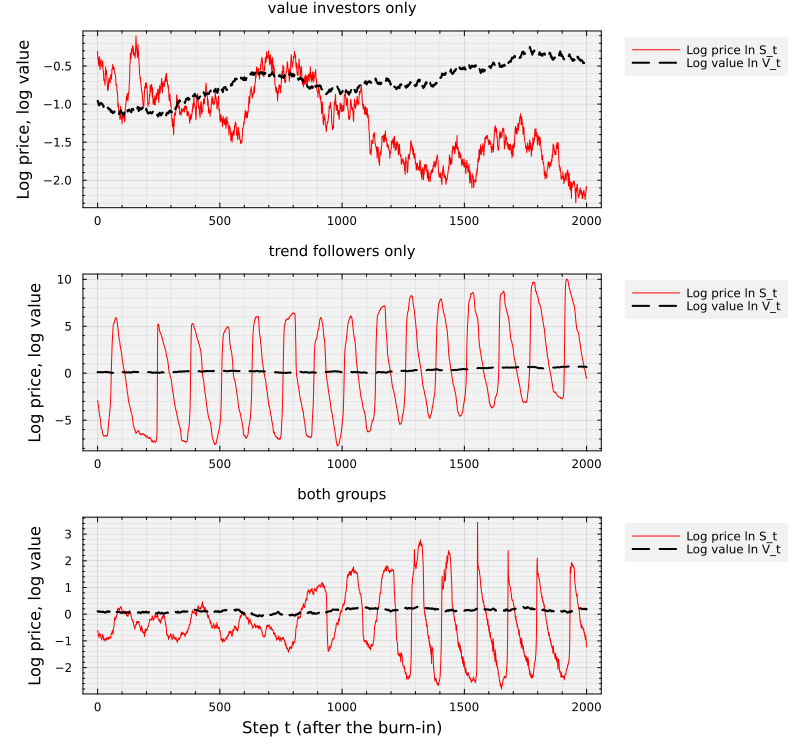

In [6]:
let

    # initialize: the first 2,000 recorded steps -
    window = 1:2_001; # ln S_t and ln V_t for t = 0, 1, ..., 2,000
    panels = []; # one panel per market

    # plot: log price and log value in each market -
    for name ∈ market_names
        result = markets[name];
        q = plot(window .- 1, result.log_price[window], lw = 1, c = :red, label = "Log price ln S_t",
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, yminorticks = true, minorgrid = true, legend = :outertopright, title = name, titlefontsize = 10)
        plot!(q, window .- 1, result.log_value[window], lw = 2, c = :black, ls = :dash, label = "Log value ln V_t") # the value
        ylabel!(q, "Log price, log value")
        push!(panels, q);
    end
    xlabel!(panels[end], "Step t (after the burn-in)")

    # show the panels, one above the other -
    plot(panels..., layout = (3, 1), size = (800, 750), left_margin = 4Plots.mm)
end

> __What do we see?__
>
> * __Value investors only:__ The price wanders around the value and stays within about two log units of it in this window. Gaps of either sign last for hundreds of steps before the price comes back.
> * __Trend followers only:__ The price ignores the value and runs through repeated cycles, a long move in one direction followed by a sharp reversal, more than ten log units from peak to trough.
> * __Both groups:__ The price stays much closer to the value than with trend followers only, but it still makes sharp moves of one to several log units, separated by quieter stretches.

Your numbers will differ if you change the constants.
___

## Task 2: Measure the Stylized Facts
In this task, we measure the stylized facts of the growth rates in the market with both groups: fat tails, the autocorrelation of the growth rates, and volatility clustering.

We measure three things:
* __Fat tails:__ the excess kurtosis, $\langle(g-\bar{g})^{4}\rangle/\sigma_{g}^{4}-3$, where $\bar{g}$ and $\sigma_{g}$ are the mean and standard deviation of the growth rates, is zero for a Normal distribution and positive when large moves are more common than a Normal distribution predicts. A q–q plot shows the same thing graphically.
* __Autocorrelation of the growth rates:__ whether a growth rate predicts the next ones.
* __Volatility clustering:__ the autocorrelation of the absolute growth rates $\lvert g_{t}\rvert$ and of the volume. Positive values mean that large moves, and heavy trading, tend to follow large moves.

[The stylized_facts_report(...) function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/adaptive/#VLQuantitativeFinancePackage.stylized_facts_report) returns the autocorrelations of the growth rates and of their absolute values at the lags we pass, the white-noise band, and a Hill estimate of the tail index. Because Farmer and Joshi show fat tails with a q–q plot and the kurtosis, we report the tail index only as an extra diagnostic.

First, let's write a short function for the excess kurtosis:

In [7]:
# excess kurtosis: the fourth moment of the standardized series, minus 3 (zero for a Normal distribution) -
excess_kurtosis(x) = mean(((x .- mean(x)) ./ std(x, corrected = false)).^4) - 3;

Now let's compute the statistics of the market with both groups and store them in the `facts_df::DataFrame` variable. We use them again in Task 3:

In [8]:
facts_df = let

    # initialize: the growth rates and the volume of the market with both groups -
    combined = markets["both groups"];
    g = combined.returns ./ Δt; # growth rates g (1/yr)
    volume = combined.value_volume .+ combined.trend_volume; # total volume per step
    report = stylized_facts_report(g; lags = lags); # autocorrelations, white-noise band, Hill tail index
    volume_acf = sample_autocorrelation(volume, lags); # autocorrelation of the volume

    # build the table: one row per statistic -
    df = DataFrame(
        statistic = ["excess kurtosis";
            ["autocorrelation of g, lag $(l)" for l ∈ lags];
            ["autocorrelation of |g|, lag $(l)" for l ∈ lags];
            ["autocorrelation of volume, lag $(l)" for l ∈ lags];
            "white-noise band (±)"; "Hill tail index (extra diagnostic)"],
        value = [excess_kurtosis(g); report.raw_acf; report.absolute_acf; volume_acf; report.white_noise_95_band; report.tail_index]
    );
    pretty_table(df; column_labels = ["statistic (both groups)", "value"], alignment = [:l, :r],
        formatters = [fmt__printf("%.3f", [2])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one row per statistic -
    @assert nrow(df) == 3 + 3*length(lags) "one row per statistic"

    # return -
    df
end;

 ------------------------------------ --------
  statistic (both groups)               value 
 ------------------------------------ --------
  excess kurtosis                      38.772
  autocorrelation of g, lag 1           0.308
  autocorrelation of g, lag 5           0.053
  autocorrelation of g, lag 20          0.003
  autocorrelation of |g|, lag 1         0.650
  autocorrelation of |g|, lag 5         0.017
  autocorrelation of |g|, lag 20       -0.044
  autocorrelation of volume, lag 1      0.552
  autocorrelation of volume, lag 5     -0.003
  autocorrelation of volume, lag 20    -0.035
  white-noise band (±)                  0.014
  Hill tail index (extra diagnostic)    4.388
 ------------------------------------ --------


> __What do we see?__
>
> * __Fat tails:__ The excess kurtosis is far above zero, the value for a Normal distribution. This means that large growth rates are much more common than a Normal distribution with the same standard deviation predicts.
> * __Autocorrelation of the growth rates:__ It is positive at lag 1, smaller at lag 5, and inside the white-noise band at lag 20.
> * __Volatility clustering:__ The absolute growth rates and the volume both have a large positive autocorrelation at lag 1. This means that large moves and heavy trading come in groups. Both autocorrelations are much smaller by lag 5.

`Unhide` the code block below to see how we made the q–q plot. Each point compares a quantile of the standardized growth rates with the same quantile of a standard Normal distribution. A Normal sample would fall on the dashed line.

Are the growth rates Normal?

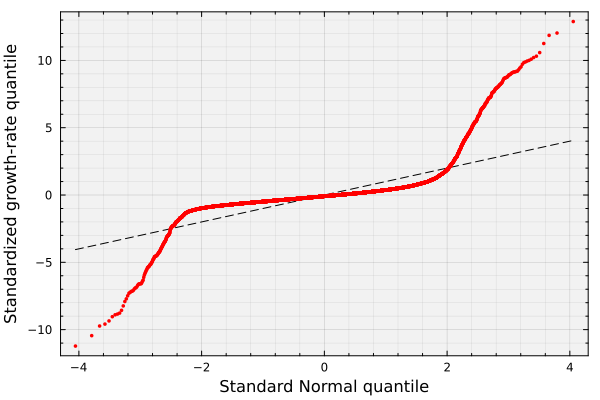

In [9]:
let

    # initialize: standardized growth rates of the market with both groups -
    g = markets["both groups"].returns ./ Δt;
    z = (g .- mean(g)) ./ std(g); # mean 0, standard deviation 1

    # plot: sample quantiles against Normal quantiles -
    qqplot(Normal(), z, qqline = :identity, ms = 2, msw = 0, c = :red, label = "",
        bg = "gray95", background_color_outside = "white", framestyle = :box,
        xminorticks = true, yminorticks = true, minorgrid = true, linecolor = :black, linestyle = :dash)

    # labels -
    xlabel!("Standard Normal quantile", fontsize = 18)
    ylabel!("Standardized growth-rate quantile", fontsize = 18)
end

> __What do we see?__
>
> * __Near the center:__ The points lie below the dashed line on the right and above it on the left. This means that most growth rates are smaller than a Normal distribution predicts.
> * __At both ends:__ The points bend sharply away from the line. The largest standardized growth rates are far beyond the $\pm 4$ that a Normal sample of this size would reach.

`Unhide` the code block below to see how we plotted the autocorrelation of the growth rates and of their absolute values at lags 1 to 50, with the white-noise band.

How long do the autocorrelations last?

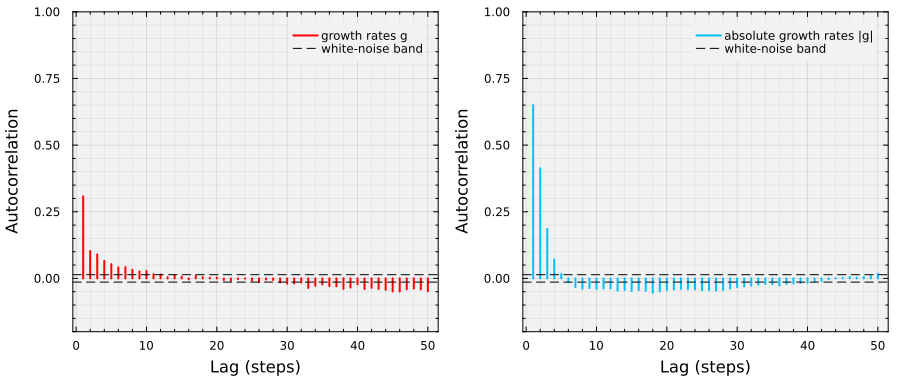

In [10]:
let

    # initialize: lags 1 to 50 and the white-noise band -
    g = markets["both groups"].returns ./ Δt; # growth rates g (1/yr)
    all_lags = collect(1:50); # lags (steps)
    band = 1.96/sqrt(length(g)); # white-noise band

    # plot: one panel for g, one for |g| -
    panels = [];
    for (series, name, color) ∈ ((g, "growth rates g", :red), (abs.(g), "absolute growth rates |g|", :deepskyblue1))
        q = plot(all_lags, sample_autocorrelation(series, all_lags), seriestype = :sticks, lw = 2, c = color, label = name,
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, yminorticks = true, minorgrid = true, ylims = (-0.2, 1.0))
        hline!(q, [band, -band], lw = 1, c = :black, ls = :dash, label = "white-noise band") # 95% band for no autocorrelation
        xlabel!(q, "Lag (steps)")
        ylabel!(q, "Autocorrelation")
        push!(panels, q);
    end

    # show the two panels side by side -
    plot(panels..., layout = (1, 2), size = (900, 380), bottom_margin = 4Plots.mm, left_margin = 4Plots.mm)
end

> __What do we see?__ Both autocorrelations are largest at lag 1 and drop quickly. The autocorrelation of the absolute growth rates falls below 0.1 within about five steps, and that of the growth rates reaches the white-noise band within about 20 steps. At longer lags, both stay within about 0.1 of zero.

Your numbers will differ if you change the constants.
___

## Task 3: Compare with a Real Ticker and Vary the Mix of Traders
In this task, we put the statistics of the simulated market next to the same statistics for the daily growth rates of `ticker`, and then vary the number of trend followers.

The daily growth rate of the ticker is $g_{t}=\frac{1}{\Delta t}\ln\left(S_{t}/S_{t-1}\right)$, where $S_{t}$ is the closing price and $\Delta t=1/252$ years.

The same $\Delta t$ puts the model's growth rates in the same units as the ticker's. We compare the shape of the statistics, not the size of the moves, because the model's noise is not calibrated to the ticker.

The excess kurtosis and the autocorrelations do not change when we multiply a series by a constant. This makes them a fair comparison of shape.

Let's compute the ticker's statistics and put them next to the simulated ones:

In [11]:
ticker_facts = let

    # initialize: the ticker's daily growth rates and volume -
    prices = dataset[ticker].close; # daily closing prices (USD/share)
    g = (1/Δt) .* diff(log.(prices)); # daily growth rates (1/yr)
    volume = Float64.(dataset[ticker].volume[2:end]); # daily volume (shares), aligned with g
    report = stylized_facts_report(g; lags = lags); # autocorrelations, white-noise band, Hill tail index
    values = [excess_kurtosis(g); report.raw_acf; report.absolute_acf; sample_autocorrelation(volume, lags); report.white_noise_95_band; report.tail_index];

    # build the table: simulated next to the ticker -
    df = DataFrame(statistic = facts_df.statistic, simulated = facts_df.value, observed = values);
    println("ticker = $(ticker): $(length(g)) daily growth rates");
    pretty_table(df; column_labels = ["statistic", "simulated (both groups)", "$(ticker) growth rates"], alignment = [:l, :r, :r],
        formatters = [fmt__printf("%.3f", [2, 3])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one growth rate per pair of closing prices -
    @assert length(g) == length(prices) - 1 "one growth rate per pair of closing prices"

    # return -
    (excess_kurtosis = values[1], acf1 = values[2], absolute_acf1 = values[2 + length(lags)])
end;

ticker = SPY: 2766 daily growth rates
 ------------------------------------ ------------------------- ------------------
  statistic                            simulated (both groups)   SPY growth rates 
 ------------------------------------ ------------------------- ------------------
  excess kurtosis                                       38.772             13.768
  autocorrelation of g, lag 1                            0.308             -0.110
  autocorrelation of g, lag 5                            0.053              0.040
  autocorrelation of g, lag 20                           0.003             -0.016
  autocorrelation of |g|, lag 1                          0.650              0.364
  autocorrelation of |g|, lag 5                          0.017              0.325
  autocorrelation of |g|, lag 20                        -0.044              0.194
  autocorrelation of volume, lag 1                       0.552              0.749
  autocorrelation of volume, lag 5                      -

> __What do we see?__
>
> * __Fat tails:__ Both excess kurtoses are far above zero, but the simulated value is several times larger than the ticker's.
> * __Autocorrelation of the growth rates:__ The ticker's lag-1 autocorrelation is small and negative, while the simulated one is positive.
> * __Volatility clustering:__ Both have a positive autocorrelation of the absolute growth rates and of the volume at lag 1. The ticker's autocorrelations stay well above zero at lags 5 and 20, which means that its clustering lasts for weeks. The simulated ones nearly vanish by lag 5.
>
> Your comparison will differ if you change `ticker`.

### Changing the mix of traders
Farmer and Joshi chose equal numbers of value investors and trend followers so that the positive autocorrelation from the trend followers would cancel the negative autocorrelation from the value investors. In our variant, the market with both groups still has a positive lag-1 autocorrelation. What happens if we change the number of trend followers?

__Sweep the number of trend followers__: We hold the value investors at 1,200 and run three markets for each number of trend followers in `trend_counts`. In the code below:
* `trend_counts::Vector{Int}` runs from 0 to 1,500 trend followers.
* As in Task 1, one random number generator `rng`, seeded with `random_seed`, supplies every market.
* The result `mix_df::DataFrame` has one row per market: the number of trend followers, the seed index, the lag-1 autocorrelation of the growth rates, the excess kurtosis, and the lag-1 autocorrelation of the absolute growth rates.

Let's run the sweep:

In [12]:
mix_df = let

    # initialize: numbers of trend followers, and one random number generator for the whole sweep -
    trend_counts = [0, 300, 600, 900, 1_200, 1_500]; # numbers of trend followers (1,200 value investors in every market)
    rng = MersenneTwister(random_seed); # reproducible sweep
    df = DataFrame(trend_number = Int[], seed = Int[], acf1 = Float64[], kurtosis = Float64[], absolute_acf1 = Float64[]); # one row per market

    # main loop: three markets for every number of trend followers -
    for n ∈ trend_counts
        for k ∈ 1:3
            model = build(MyFarmerJoshiMarketModel, (trend_number = n, σ_S = σ_S, σ_v = σ_v, Δt = Δt, rng = rng)); # new random traders
            g = solve(model; number_of_steps = number_of_steps, burn_in = burn_in, rng = rng).returns ./ Δt; # growth rates g (1/yr)
            push!(df, (n, k, sample_autocorrelation(g, [1])[1], excess_kurtosis(g), sample_autocorrelation(abs.(g), [1])[1]));
        end
    end

    # show the averages over the three markets -
    means = combine(groupby(df, :trend_number, sort = true), :acf1 => mean => :acf1, :kurtosis => mean => :kurtosis, :absolute_acf1 => mean => :absolute_acf1);
    pretty_table(means; column_labels = ["trend followers", "lag-1 autocorrelation of g", "excess kurtosis", "lag-1 autocorrelation of |g|"],
        alignment = [:r, :r, :r, :r], formatters = [fmt__printf("%.3f", [2, 3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);

    # checks: one row per market -
    @assert nrow(df) == 3*length(trend_counts) "one row per market"

    # return -
    df
end;

 ----------------- ---------------------------- ----------------- ------------------------------
  trend followers   lag-1 autocorrelation of g   excess kurtosis   lag-1 autocorrelation of |g| 
 ----------------- ---------------------------- ----------------- ------------------------------
                0                       -0.031             0.076                          0.014
              300                       -0.012             0.121                          0.009
              600                        0.021             0.181                          0.025
              900                        0.195            31.278                          0.253
             1200                        0.246            46.466                          0.675
             1500                        0.292            41.321                          0.700
 ----------------- ---------------------------- ----------------- ------------------------------


The table shows the averages over three markets. `Unhide` the code block below to see how we plotted each market's three statistics against the number of trend followers, with the ticker's values as dashed lines.

Can one mix of traders match the ticker on all three statistics?

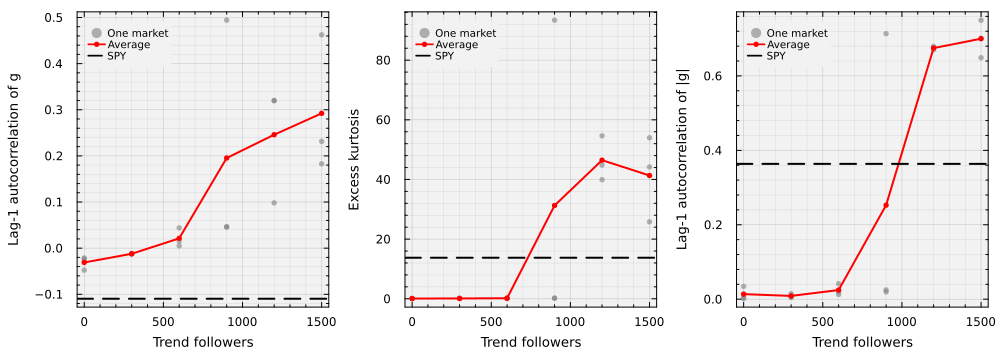

In [13]:
let

    # initialize: the statistic in each panel and the ticker's value of it -
    stats = [(:acf1, "Lag-1 autocorrelation of g", ticker_facts.acf1),
        (:kurtosis, "Excess kurtosis", ticker_facts.excess_kurtosis),
        (:absolute_acf1, "Lag-1 autocorrelation of |g|", ticker_facts.absolute_acf1)];
    means = combine(groupby(mix_df, :trend_number, sort = true), [s for (s, _, _) ∈ stats] .=> mean .=> [s for (s, _, _) ∈ stats]); # averages

    # plot: one panel per statistic -
    panels = [];
    for (s, name, observed) ∈ stats
        q = scatter(mix_df.trend_number, mix_df[!, s], ms = 3, msw = 0, c = :gray50, alpha = 0.6, label = "One market",
            bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent,
            xminorticks = true, yminorticks = true, minorgrid = true, legend = :topleft, legendfontsize = 7)
        plot!(q, means.trend_number, means[!, s], lw = 2, c = :red, marker = :circle, ms = 3, msw = 0, label = "Average") # averages
        hline!(q, [observed], lw = 2, c = :black, ls = :dash, label = ticker) # the ticker's value
        xlabel!(q, "Trend followers")
        ylabel!(q, name, guidefontsize = 9)
        push!(panels, q);
    end

    # show the three panels side by side -
    plot(panels..., layout = (1, 3), size = (1000, 360), bottom_margin = 6Plots.mm, left_margin = 5Plots.mm)
end

> __What do we see?__
>
> * __Few trend followers:__ With 600 or fewer trend followers, the excess kurtosis, the autocorrelation of the absolute growth rates, and the lag-1 autocorrelation of the growth rates all stay close to zero.
> * __Many trend followers:__ With 900 trend followers, the markets differ widely, some near zero and some far above it on each statistic. With 1,200 or more, every market has a large kurtosis and strong clustering, past the ticker's values.
>
>   In these markets, the lag-1 autocorrelation of the growth rates differs widely from one market to the next, and it stays above the ticker's value.
> * __No single mix:__ At every number of trend followers in our sweep, the averages miss the ticker by a wide margin on at least one of the three statistics.

Your numbers will differ if you change the constants. Try `σ_S = 0.55` or `σ_S = 1.6`, or a different `ticker`, and rerun the notebook.
___

## Summary
In this example, we simulated the Farmer–Joshi market with value investors, trend followers, and both, measured the stylized facts of the market with both groups, and compared them with the growth rates of a real ticker.

> __Key Takeaways:__
>
> * __Each trading rule leaves its own mark on the price:__ We simulated markets with one group of traders at a time. Value investors kept the price near the value, and their trading gave the growth rates a small negative autocorrelation.
>
>   Trend followers let the price run far from the value in repeated cycles. They gave the growth rates a large positive autocorrelation.
> * __The two groups together produce fat tails and volatility clustering:__ We measured the market with both groups and found a large excess kurtosis, a q–q plot that bends away from the Normal line at the extremes, and positive autocorrelation of the absolute growth rates and of the volume.
>
>   None of these patterns was put into the model. They come from the traders' rules and the market maker.
> * __The model matches some stylized facts but not all at once:__ We compared the simulated statistics with a real ticker and varied the number of trend followers. Fat tails and volatility clustering appeared only once there were enough trend followers.
>
>   The clustering then faded within a few steps instead of lasting for weeks as in the real growth rates. The autocorrelation of the growth rates changed widely from one set of random traders to the next.

The traders, the signals they watch, their threshold rules, the net order, and the price that feeds back into the next signals are the five parts of an agent-based model from the lecture.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___